<a href="https://colab.research.google.com/github/Gitech247/MODULE_2_KNOWLEDGE_CHECK/blob/Module_2-Case_Exercise-1/MODULE_2_CASE_EXERCISE1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DESIGN ENVELOPE CONSTRUCTION AND VISUALIZATION**
##**Question 1**:Implement the pressure_temperature_envelope() function from Section 2.2.2 with full documentation and error handling.

In [17]:
import pandas as pd

def pressure_temperature_envelope(
    pressure_psi: int | float,
    temperature_c: int | float,
    hydrate_temperature_c: int | float,
    minimum_pressure_psi: int | float,
    maximum_temperature_c: int | float,
    maximum_pressure_psi: int | float = 4467.0,
    tolerance: float = 1e-6
) -> dict:
    """
    Evaluate whether a subsea asset's operating pressure and temperature
    satisfy its specified pressure-temperature operating envelope.
    """
    inputs = {
        "pressure_psi": pressure_psi,
        "temperature_c": temperature_c,
        "hydrate_temperature_c": hydrate_temperature_c,
        "minimum_pressure_psi": minimum_pressure_psi,
        "maximum_temperature_c": maximum_temperature_c,
        "maximum_pressure_psi": maximum_pressure_psi,
        "tolerance": tolerance,
    }

    for name, value in inputs.items():
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise TypeError(f"{name} must be an integer or float; received {type(value).__name__}.")
        if value != value or value in (float('inf'), float('-inf')):
            raise ValueError(f"{name} must be finite; received {value!r}.")

    if minimum_pressure_psi < 0:
        raise ValueError("minimum_pressure_psi cannot be negative.")
    if maximum_pressure_psi <= 0:
        raise ValueError("maximum_pressure_psi must be greater than zero.")
    if minimum_pressure_psi >= maximum_pressure_psi:
        raise ValueError("minimum_pressure_psi must be less than maximum_pressure_psi.")
    if maximum_temperature_c <= hydrate_temperature_c:
        raise ValueError("maximum_temperature_c must be greater than hydrate_temperature_c.")
    if tolerance < 0:
        raise ValueError("tolerance cannot be negative.")
    if pressure_psi < 0:
        raise ValueError("Operating pressure cannot be negative.")

    checks = {
        "maximum_pressure": {
            "passed": pressure_psi <= maximum_pressure_psi + tolerance,
            "actual": pressure_psi,
            "limit": maximum_pressure_psi,
            "unit": "psi",
            "description": "Maximum allowable operating pressure",
        },
        "minimum_pressure": {
            "passed": pressure_psi >= minimum_pressure_psi - tolerance,
            "actual": pressure_psi,
            "limit": minimum_pressure_psi,
            "unit": "psi",
            "description": "Minimum pressure for flow stability",
        },
        "minimum_temperature": {
            "passed": temperature_c > hydrate_temperature_c,
            "actual": temperature_c,
            "limit": hydrate_temperature_c,
            "unit": "°C",
            "description": "Temperature relative to hydrate formation",
        },
        "maximum_temperature": {
            "passed": temperature_c <= maximum_temperature_c,
            "actual": temperature_c,
            "limit": maximum_temperature_c,
            "unit": "°C",
            "description": "Maximum allowable material temperature",
        },
    }

    violations = [name for name, result in checks.items() if not result["passed"]]
    warnings = []

    pressure_margin = maximum_pressure_psi - pressure_psi
    temperature_margin = temperature_c - hydrate_temperature_c

    if 0 <= pressure_margin <= 0.05 * maximum_pressure_psi:
        warnings.append("Operating pressure is within 5% of the maximum pressure limit.")
    if 0 < temperature_margin <= 2.0:
        warnings.append("Operating temperature is within 2°C above the hydrate formation temperature. Confirm safety margin.")
    if 0 <= (maximum_temperature_c - temperature_c) <= 2.0:
        warnings.append("Operating temperature is within 2°C of the maximum allowable temperature.")

    within_envelope = len(violations) == 0

    if not within_envelope:
        status = "OUTSIDE_ENVELOPE"
        message = "One or more engineering boundaries have been breached. Review operational procedures."
    elif warnings:
        status = "WARNING"
        message = "All defined boundary checks pass, but the operating point is close to one or more limits."
    else:
        status = "SAFE"
        message = "All defined pressure-temperature boundary checks pass safely."

    return {
        "status": status,
        "within_envelope": within_envelope,
        "pressure_psi": pressure_psi,
        "temperature_c": temperature_c,
        "checks": checks,
        "violations": violations,
        "warnings": warnings,
        "message": message,
    }

test_result = pressure_temperature_envelope(
    pressure_psi=4300,
    temperature_c=62,
    hydrate_temperature_c=61.2,
    minimum_pressure_psi=3000,
    maximum_temperature_c=80,
    maximum_pressure_psi=4467
)

checks_df = pd.DataFrame.from_dict(test_result["checks"], orient="index")
checks_df.index.name = "Boundary Metric"
checks_df.reset_index(inplace=True)

summary_data = {
    "Metric Group": [
        "Overall Status",
        "Within Envelope",
        "Operating Pressure",
        "Operating Temperature",
        "Active Warnings",
        "Message"
    ],
    "Value": [
        test_result["status"],
        str(test_result["within_envelope"]),
        f"{test_result['pressure_psi']} psi",
        f"{test_result['temperature_c']} °C",
        ", ".join(test_result["warnings"]) if test_result["warnings"] else "None",
        test_result["message"]
    ]
}
summary_df = pd.DataFrame(summary_data)

print("=== SUBSEA OPERATIONAL STATUS REPORT ===")
display(summary_df)

print("\n=== DETAILED BOUNDARY VERIFICATION CHECKS ===")
display(checks_df)

=== SUBSEA OPERATIONAL STATUS REPORT ===


,Metric Group,Value
0,Overall Status,WARNING
1,Within Envelope,True
2,Operating Pressure,4300 psi
3,Operating Temperature,62 °C
4,Active Warnings,Operating pressure is within 5% of the maximum...
5,Message,"All defined boundary checks pass, but the oper..."



=== DETAILED BOUNDARY VERIFICATION CHECKS ===


,Boundary Metric,passed,actual,limit,unit,description
0,maximum_pressure,True,4300,4467.0,psi,Maximum allowable operating pressure
1,minimum_pressure,True,4300,3000.0,psi,Minimum pressure for flow stability
2,minimum_temperature,True,62,61.2,°C,Temperature relative to hydrate formation
3,maximum_temperature,True,62,80.0,°C,Maximum allowable material temperature


# **Question 2:**
Create a 2D P-T envelope plot showing the safe operating region, hydrate curve, WAT line, and MAOP boundary. Plot the six jumper operating points from Table 2.9 on the envelope.

,Jumper,Pressure_psi,Temperature_C,Corrosion_Rate_mm_yr,Water_Cut_pct
0,J-001,4200,65,0.15,32
1,J-002,4400,72,0.19,45
2,J-003,3800,58,0.12,28
3,J-004,3200,55,0.14,38
4,J-005,4467,78,0.26,62
5,J-006,4100,68,0.17,40


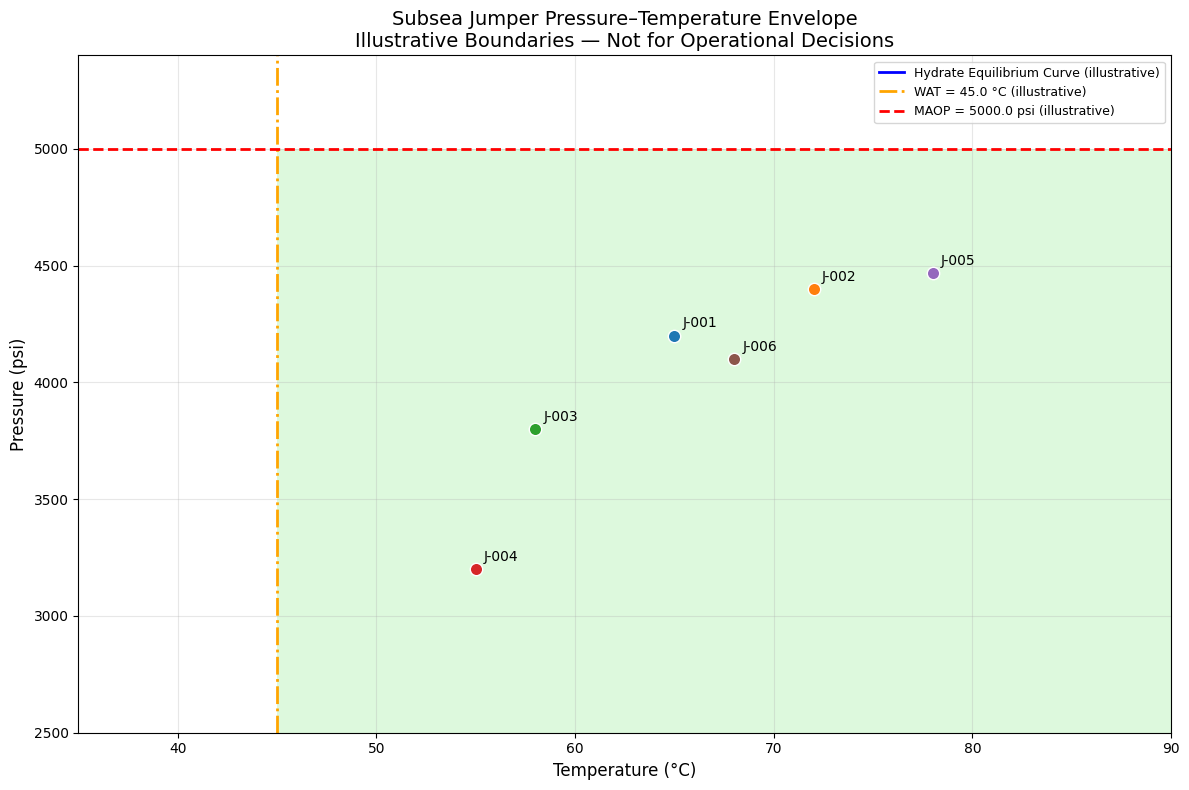

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define the missing limit parameters based on the plot boundaries
WAT_C = 45.0  # Wax Appearance Temperature boundary
MAOP_PSI = 5000.0  # Maximum Allowable Operating Pressure boundary

# Define variables for plotting the illustrative hydrate equilibrium curve
pressure_curve = np.linspace(2500, 5400, 300)
hydrate_temperature = 20 + (pressure_curve - 2500) * (8 / 2700)

# Jumper operating data transcribed from your table
df = pd.DataFrame({
    "Jumper": ["J-001", "J-002", "J-003",
               "J-004", "J-005", "J-006"],
    "Pressure_psi": [4200, 4400, 3800, 3200, 4467, 4100],
    "Temperature_C": [65, 72, 58, 55, 78, 68],
    "Corrosion_Rate_mm_yr": [0.15, 0.19, 0.12, 0.14, 0.26, 0.17],
    "Water_Cut_pct": [32, 45, 28, 38, 62, 40]
})

display(df)

fig, ax = plt.subplots(figsize=(12, 8))

# Plot the illustrative hydrate equilibrium curve
ax.plot(
    hydrate_temperature,
    pressure_curve,
    color="blue",
    linewidth=2,
    label="Hydrate Equilibrium Curve (illustrative)"
)

# Plot the WAT boundary
ax.axvline(
    WAT_C,
    color="orange",
    linestyle="-.",
    linewidth=2,
    label=f"WAT = {WAT_C} °C (illustrative)"
)

# Plot the MAOP boundary
ax.axhline(
    MAOP_PSI,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"MAOP = {MAOP_PSI} psi (illustrative)"
)

# Define plotting grid
temperature_grid = np.linspace(35, 90, 300)
pressure_grid = np.linspace(2500, 5400, 300)

T, P = np.meshgrid(temperature_grid, pressure_grid)

# Illustrative safe-region criteria:
hydrate_limit = 20 + (P - 2500) * (8 / 2700)

safe_region = (
    (T >= WAT_C)
    & (T >= hydrate_limit)
    & (P <= MAOP_PSI)
)

# Shade the illustrative safe region
ax.contourf(
    T,
    P,
    safe_region.astype(int),
    levels=[0.5, 1.5],
    colors=["lightgreen"],
    alpha=0.3
)

# Plot and label the six jumper operating points
for _, row in df.iterrows():
    ax.scatter(
        row["Temperature_C"],
        row["Pressure_psi"],
        s=80,
        edgecolor="white",
        zorder=5
    )

    ax.annotate(
        row["Jumper"],
        (row["Temperature_C"], row["Pressure_psi"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=10
    )

ax.set_xlabel("Temperature (°C)", fontsize=12)
ax.set_ylabel("Pressure (psi)", fontsize=12)

ax.set_title(
    "Subsea Jumper Pressure–Temperature Envelope\n"
    "Illustrative Boundaries — Not for Operational Decisions",
    fontsize=14
)

ax.set_xlim(35, 90)
ax.set_ylim(2500, 5400)
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)

plt.tight_layout()
plt.show()

# **Question 3:**  Extend to a 3-parameter envelope (P-T-flow rate) and create a 3D scatter plot showing operating points coloured by envelope status.

Evaluated Jumper Operating Points (3-Parameter Envelope):


,Jumper,Pressure_psi,Temperature_C,Corrosion_Rate_mm_yr,Water_Cut_pct,Flow_Rate,Status
0,J-001,4200,65,0.15,32,12.0,WITHIN_ENVELOPE
1,J-002,4400,72,0.19,45,22.0,WITHIN_ENVELOPE
2,J-003,3800,58,0.12,28,18.0,WITHIN_ENVELOPE
3,J-004,3200,55,0.14,38,4.0,OUTSIDE_ENVELOPE
4,J-005,4467,78,0.26,62,26.0,OUTSIDE_ENVELOPE
5,J-006,4100,68,0.17,40,15.0,WITHIN_ENVELOPE


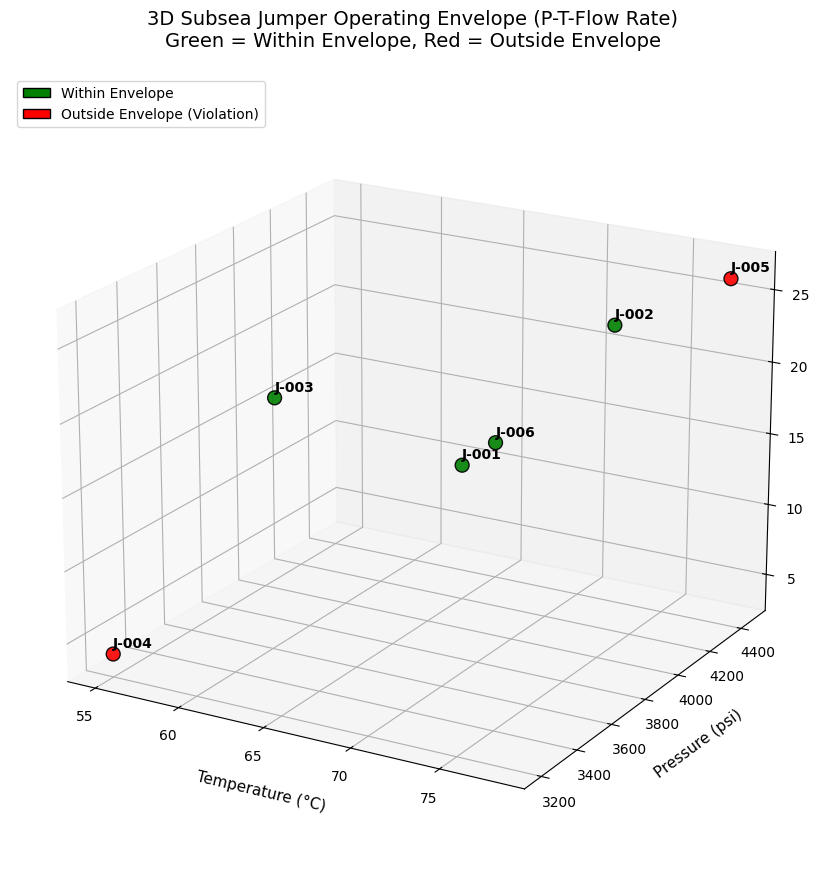

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Define limits for the 3-parameter envelope
# Using existing limits for pressure and temperature, and introducing representative flow rate limits.
WAT_C = 45.0          # Min temperature
MAOP_PSI = 5000.0      # Max pressure
MIN_FLOW = 5.0         # Min flow rate
MAX_FLOW = 25.0        # Max flow rate

# Extend jumper dataset with illustrative flow rate values
try:
    df_3d = df.copy()
except NameError:
    df_3d = pd.DataFrame({
        "Jumper": ["J-001", "J-002", "J-003", "J-004", "J-005", "J-006"],
        "Pressure_psi": [4200, 4400, 3800, 3200, 4467, 4100],
        "Temperature_C": [65, 72, 58, 55, 78, 68]
    })

# Let's add illustrative flow rates for each jumper
df_3d["Flow_Rate"] = [12.0, 22.0, 18.0, 4.0, 26.0, 15.0]

# 2. Check 3-parameter envelope status
def check_3d_envelope(row):
    p = row["Pressure_psi"]
    t = row["Temperature_C"]
    q = row["Flow_Rate"]

    # Hydrate line limit verification
    hydrate_limit_temp = 20 + (p - 2500) * (8 / 2700)

    is_safe = (
        (t >= WAT_C) &
        (t >= hydrate_limit_temp) &
        (p <= MAOP_PSI) &
        (q >= MIN_FLOW) &
        (q <= MAX_FLOW)
    )
    return "WITHIN_ENVELOPE" if is_safe else "OUTSIDE_ENVELOPE"

df_3d["Status"] = df_3d.apply(check_3d_envelope, axis=1)

# Display the evaluation dataset
print("Evaluated Jumper Operating Points (3-Parameter Envelope):")
display(df_3d)

# 3. Create the 3D Scatter Plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Set colors based on status
colors = df_3d["Status"].map({"WITHIN_ENVELOPE": "green", "OUTSIDE_ENVELOPE": "red"})

# Plot the points
scatter = ax.scatter(
    df_3d["Temperature_C"],
    df_3d["Pressure_psi"],
    df_3d["Flow_Rate"],
    c=colors,
    s=100,
    edgecolor='k',
    alpha=0.9
)

# Annotate the points
for _, row in df_3d.iterrows():
    ax.text(
        row["Temperature_C"],
        row["Pressure_psi"],
        row["Flow_Rate"] + 0.5,
        row["Jumper"],
        fontsize=10,
        fontweight='bold'
    )

# Set labels
ax.set_xlabel('Temperature (°C)', fontsize=11, labelpad=10)
ax.set_ylabel('Pressure (psi)', fontsize=11, labelpad=10)
ax.set_zlabel('Flow Rate', fontsize=11, labelpad=10)
ax.set_title('3D Subsea Jumper Operating Envelope (P-T-Flow Rate)\nGreen = Within Envelope, Red = Outside Envelope', fontsize=14, pad=20)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='green', edgecolor='k', label='Within Envelope'),
    Patch(facecolor='red', edgecolor='k', label='Outside Envelope (Violation)')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10)

# Adjust viewing angle for better visualization
ax.view_init(elev=20, azim=-60)

plt.tight_layout()
plt.show()

#**Question 4:**  Write a function that takes a DataFrame of operating data and returns the percentage of time each parameter was within the design envelope.

In [9]:
import pandas as pd


def percentage_within_envelope(
    df,
    design_limits,
    parameter_columns=None
):
    """
    Calculate the percentage of recorded operating time each parameter
    remains within its specified design envelope.

    Parameters
    ----------
    df : pandas.DataFrame
        Operating data containing one column per parameter.

    design_limits : dict
        Dictionary defining the minimum and maximum design limits
        for each parameter.

        Example:
        {
            "pressure_psi": {"min": 500, "max": 4467},
            "temperature_c": {"min": 15, "max": 80},
            "flow_rate": {"min": 150, "max": 1200}
        }

    parameter_columns : list, optional
        List of DataFrame columns to evaluate. If None, all parameters
        specified in design_limits are evaluated.

    Returns
    -------
    pandas.DataFrame
        A summary table containing:
        - Parameter name
        - Number of valid readings
        - Number of readings within the envelope
        - Number of readings outside the envelope
        - Percentage within the envelope
        - Percentage outside the envelope

    Notes
    -----
    A reading is within the envelope when:
        minimum limit <= reading <= maximum limit

    Missing readings are excluded from the percentage calculation.
    Each valid reading is weighted equally. For irregularly sampled
    data, a time-weighted calculation may be more appropriate.
    """

    # 1. Validate the DataFrame
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if df.empty:
        raise ValueError("The DataFrame is empty.")

    if not df.columns.is_unique:
        raise ValueError("The DataFrame must have unique column names.")

    if not isinstance(design_limits, dict) or not design_limits:
        raise ValueError("design_limits must be a non-empty dictionary.")

    # 2. Determine which parameters to evaluate
    if parameter_columns is None:
        parameter_columns = list(design_limits.keys())

    if not parameter_columns:
        raise ValueError("At least one parameter must be specified.")

    if len(parameter_columns) != len(set(parameter_columns)):
        raise ValueError("parameter_columns contains duplicate names.")

    results = []

    # 3. Evaluate each parameter
    for parameter in parameter_columns:

        if parameter not in df.columns:
            raise ValueError(
                f"Parameter '{parameter}' is missing from the DataFrame."
            )

        if parameter not in design_limits:
            raise ValueError(
                f"No design limits provided for '{parameter}'."
            )

        limits = design_limits[parameter]

        if not isinstance(limits, dict):
            raise TypeError(
                f"Design limits for '{parameter}' must be a dictionary."
            )

        if "min" not in limits or "max" not in limits:
            raise ValueError(
                f"'{parameter}' must have both 'min' and 'max' limits."
            )

        minimum = limits["min"]
        maximum = limits["max"]

        # Reject invalid design limits
        if (
            isinstance(minimum, bool)
            or isinstance(maximum, bool)
            or not isinstance(minimum, (int, float))
            or not isinstance(maximum, (int, float))
        ):
            raise TypeError(
                f"Limits for '{parameter}' must be numeric."
            )

        if not pd.notna(minimum) or not pd.notna(maximum):
            raise ValueError(
                f"Limits for '{parameter}' cannot be missing."
            )

        if minimum >= maximum:
            raise ValueError(
                f"Minimum limit must be less than maximum limit "
                f"for '{parameter}'."
            )

        # Convert readings to numeric values.
        # Non-numeric and infinite values are treated as invalid readings.
        readings = pd.to_numeric(df[parameter], errors="coerce")
        readings = readings.where(
            readings.map(lambda x: pd.isna(x) or abs(x) != float("inf"))
        )

        valid_readings = readings.dropna()
        total_valid = len(valid_readings)

        if total_valid == 0:
            results.append({
                "parameter": parameter,
                "valid_readings": 0,
                "within_envelope": 0,
                "outside_envelope": 0,
                "percentage_within": float("nan"),
                "percentage_outside": float("nan")
            })
            continue

        # A reading passes if it is between the minimum and maximum.
        within = (
            (valid_readings >= minimum)
            & (valid_readings <= maximum)
        )

        within_count = int(within.sum())
        outside_count = total_valid - within_count

        percentage_within = (
            within_count / total_valid
        ) * 100

        percentage_outside = (
            outside_count / total_valid
        ) * 100

        results.append({
            "parameter": parameter,
            "valid_readings": total_valid,
            "within_envelope": within_count,
            "outside_envelope": outside_count,
            "percentage_within": round(percentage_within, 2),
            "percentage_outside": round(percentage_outside, 2)
        })

    return pd.DataFrame(results)
#Create sample operating data
data = {
    "pressure_psi": [450, 600, 3000, 4500, np.nan, 4000],
    "temperature_c": [20, 25, 100, 50, 60, np.inf],
    "flow_rate": [200, 150, 1200, 1300, 500, 600]
}
df_sample = pd.DataFrame(data)

# Define design limits
limits = {
    "pressure_psi": {"min": 500, "max": 4467},
    "temperature_c": {"min": 15, "max": 80},
    "flow_rate": {"min": 150, "max": 1200}
}

# Execute the function and display the results
results_df = percentage_within_envelope(df_sample, limits)
display(results_df)

,parameter,valid_readings,within_envelope,outside_envelope,percentage_within,percentage_outside
0,pressure_psi,5,3,2,60.00,40.00
1,temperature_c,5,4,1,80.00,20.00
2,flow_rate,6,5,1,83.33,16.67
